# Project 1 - Recomender system

## Introduction
Project nr 1 inculdes an implementation of the recommendation system for movie ratings using various algorithms such as NMF, SVD, iterated SVD and SGD. All of these methods will be described in this report. The models based on these methods will be presented with the achieved results.


Data with the movie ratings was downloaded from https://grouplens.org/datasets/movielens/. We use only the file ratings.csv from ml-latest-small.zip.
That file contains approximately 100,000 ratings – about 600 users have rated around 9,000 movies.


The format of dataset is shown below:

In [6]:
import pandas as pd

df = pd.read_csv("data/ratings.csv")
print(df)

        userId  movieId  rating   timestamp
0            1        1     4.0   964982703
1            1        3     4.0   964981247
2            1        6     4.0   964982224
3            1       47     5.0   964983815
4            1       50     5.0   964982931
...        ...      ...     ...         ...
100831     610   166534     4.0  1493848402
100832     610   168248     5.0  1493850091
100833     610   168250     5.0  1494273047
100834     610   168252     5.0  1493846352
100835     610   170875     3.0  1493846415

[100836 rows x 4 columns]


The column 'user_Id' is a unique user identifier, 'movieId' is a unique movie identifier, and rating is an integer rating from 0 to 5 - although ratings includes half points, e.g. 3.5, 4.5. The column named timestamp' will not be used.

In all models I use this data converted into matrices. $Z$ is a matrix containing
the training ratings – a matrix of size n × d, where n is the number of users and d is the number of movies. It is important to note that many entries of $Z$ are undefined. The task of the recommender system is to predict values for those entries as good as possible.

Let us see the available data.

Basic statistics for ratings:
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64
median: 3.5
mean: 3.501556983616962


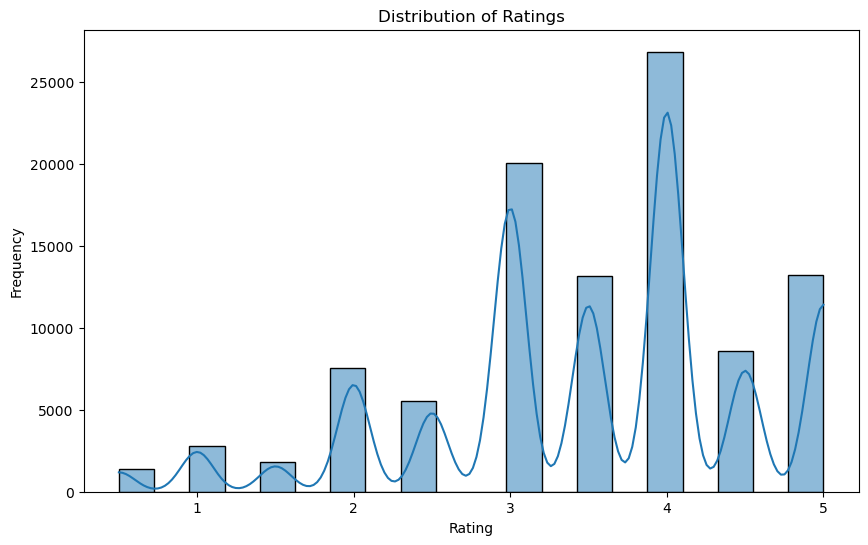

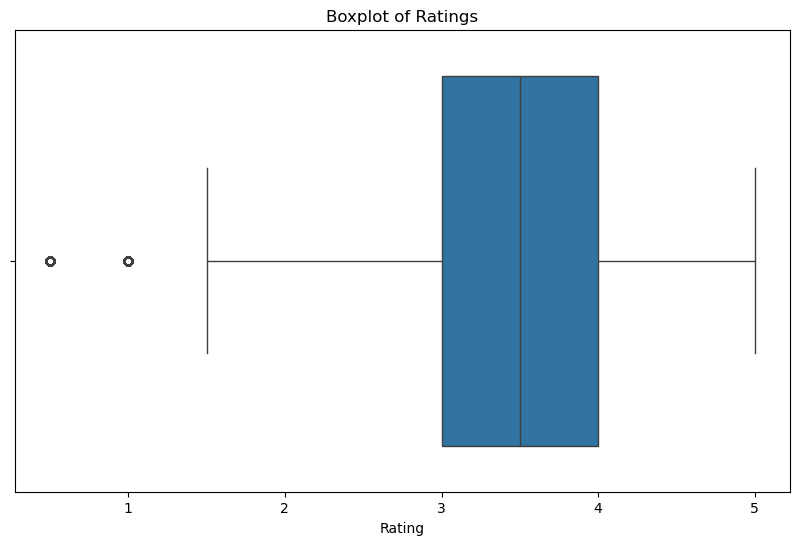

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def check_data_distribution(train_file):
    """
    This function checks the distribution of ratings in the dataset by providing 
    statistical summary and plots (histogram and boxplot).
    
    Parameters:
        - train_file (str): Path to the training CSV file containing user, movie, and rating columns.
    """
    # Load the dataset
    df = pd.read_csv(train_file)

    # Display basic statistics for the ratings
    print("Basic statistics for ratings:")
    print(df['rating'].describe())
    print(f'median: {df['rating'].median()}')
    print(f'mean: {df['rating'].mean()}')
    
    # Plot histogram
    plt.figure(figsize=(10, 6))
    sns.histplot(df['rating'], kde=True, bins=20)
    plt.title("Distribution of Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Frequency")
    plt.show()

    # Plot boxplot
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df['rating'])
    plt.title("Boxplot of Ratings")
    plt.xlabel("Rating")
    plt.show()


train_file = "data/ratings.csv"
check_data_distribution(train_file)

We can see from the histogram and the boxplot that the distribution of dataset is left-skewed. This could influence the selection of an appropriate prediction tool - the median of existing data may be a better choice than the mean. However, the median and the mean are very close values (both close to 3.5). Hence, I assume that the choice between the mean and the median does not matter much in this case.

Another thing worth noting is that there are no ratings equal to 0.0. That means that we can replace undefined values in matrix $Z$ with zeros as a first guess without corrupting the data.

Before I continue to describe the way I chose to built $Z$ matrix from data, I will discuss the algorithms used for prediction - NMF, SVD, iterated SVD and SGD.

## Algorithms description

### NMF
Non-negative Matrix Factorization (NMF) is a matrix decomposition technique that aims to factorize a non-negative matrix ($Z$) into two lower-rank matrices($W$, $H$) such that all elements of the matrices are non-negative. 

Given a matrix  $ Z \in \mathbb{R}^{n \times d} $ NMF seeks to find two matrices $ W \in \mathbb{R}^{n \times r} $ and $ H \in \mathbb{R}^{r \times d} $ such that:
$$
Z \approx W \cdot H
$$

subject to:
$$
W \geq 0, \quad H \geq 0.
$$

In the context of movie recommendation system, the input is a rating matrix $Z$ where rows represent users and columns represent movies. Each element of $Z$ corresponds to a user's rating of a movie (missing ratings can be treated as unknowns).

The reconstructed matrix $ \hat{Z} = W \cdot H $ approximates the original matrix, and the factorization can be used to predict missing entries.

### SVD
Singular Value Decomposition (SVD) is a general matrix decomposition technique that decomposes any matrix $Z$ into three components:

$$
Z = U \Sigma V^T
$$

Where:
- $U$ is $n \times d$ matrix with orthonormal columns ( $U^TU = \mathbf{I} $ ),
- $V$ is a $d \times d$ matrix also with orthonormal columns,
- $ \Sigma $ is a $d \times d$ diagonal matrix with non-negative entries.

To reduce dimensionality, we use only the top $ r$ components ( $r \leq d$ and componenst are sorted by lambda size):

$$
Z_r = U_r \Sigma_r V_r^T
$$

This $ Z_r $ is a low-rank approximation of the original matrix and can be used to fill missing ratings.

We also denote:
$$
Z = U \cdot H
$$
where $H = \Sigma \cdot V^T$.


In our case, we can specify that:
- $ U $ contains the left singular vectors (user features),
- $ \Sigma $ is a diagonal matrix of singular values (importance of features),
- $ V $ contains the right singular vectors (movie features).


### Iterated SVD
Iterated SVD is an algorithm that specifically work on missing values in matrix $Z$. It takes the initial matrix (with real values and some initial values for missing entries) and performs SVD on it. 
Then, it computes an approximation of the matrix $\hat{Z}$, and replaces the elements that originally had known values with their original values. In this way, with each iteration of the loop (each new SVD decomposition), it gradually optimizes the values in the positions where data was originally missing.

Iterative Procedure:
1. Fill missing values with initial values.
2. Perform SVD to obtain $\hat{Z}$.
3. Replace values in $\hat{Z}$ with real values from $Z$.
4. Repeat steps 2–3 until convergence or max iterations.

This process uses SVD and makes better results for matrices with a significant number of missing values.


### SGD

Stochastic Gradient Descent (SGD) is an optimizing algorithm used to minimize given loss function by iteratively updating parameters in the direction of the negative gradient. The gradient of a loss function is a vector that contains the partial derivatives of the loss function with respect to each of the model's parameter - in our case they are values from the matrices $ W $ and $ H $. SGD optimizes these matrices by minimizing the reconstruction error.


Let:
- $ Z $ be the original rating matrix, where $ Z_{ij} $ is the rating of user $ i $ for movie $ j $,
- $ W \in \mathbb{R}^{n \times r} $ be the user feature matrix,
- $ H \in \mathbb{R}^{r \times d} $ be the movie feature matrix,
- $ \hat{Z} = WH $ be the reconstructed matrix.

The goal is to minimize the loss function:

$$
\mathcal{L} = \sum_{(i,j) \in \Omega} (Z_{ij} - (WH)_{ij})^2 + \lambda ( \|W\|^2 + \|H\|^2 )
$$

where:
- $ \Omega $ is the set of ratings,
- $ \lambda $ is a regularization parameter to prevent overfitting.

Iterative procedure:
1. Initialize $ W $ and $ H $ with random values.
2. For each rating $ Z_{ij} $ compute the prediction error:
   $$
   e_{ij} = Z_{ij} - w_i^\top h_j
   $$
3. Update the feature vectors:
   $$
   w_i \leftarrow w_i + \eta (e_{ij} h_j - \lambda w_i)
   $$
   $$
   h_j \leftarrow h_j + \eta (e_{ij} w_i - \lambda h_j)
   $$
   where $ \eta $ is the learning rate.
4. Repeat until convergence or for given number of epochs.

SGD updates parameters based on individual rating entries, making it scalable and suitable for large, sparse datasets.

In our case $ \lambda $ simply equals 0.

## Methods of imputing the missing data
The implementation of each method (NMF, SVD, iterated SVD, and SGD) requires a fully populated matrix $Z$. Therefore, missing values must first be replaced. There are a few simple methods for handling missing values:
* Filling missing entries with 0,
* Replacing missing values with the average rating of the corresponding movie,
* Replacing missing values with the average rating given by the user.

Average values can be define as mean or median. As I meationed before in this case it shouldn't matter. I'm gonna choose mean because it has better statistical properties.

Every approach has its drawbacks. Filling missing values with 0 is the easiest approach and the most flawed. Most of the data in our dataset with ratings is missing so it can cause a lot of damage in predictions. Zero values ​​would significantly lower the prediction values ​​of the ratings.

Replacing missing values with the average rating of the corresponding movie or the average rating given by the user are much better approach. But chosing one of those makes the other category irrelevant. In first method we take into consideration only the objective rating of a movie, and in second we take average rating made by a user. Also available data have many missing values, which means that we sometimes can't even calculate one of those.

I decided to take another approach and calculate mean from average rating of the movies and avarage rating from the user. In that case we consider both informations. And also if one of these averages cannot be computed, we simply take only the second value. In case there are no information about the movie or the user, I uses the average from full matrix $Z$.

Function 'build_rating_matrix' create matrix $Z$ based on dataset as I described above. It also returns mapping of user_Id and movie_Id and mask. In mask we store information which elements of $Z$ are the original values. 

In [13]:
from modules.helper_functions import build_rating_matrix

Z, user_map, movie_map, mask = build_rating_matrix("data/ratings.csv")
print(Z)

[[4.        3.8990986 4.        ... 3.9331896 3.9331896 4.18319  ]
 [3.934603  3.690047  3.6039457 ... 3.724138  3.724138  3.974138 ]
 [3.1784139 2.933858  2.8477564 ... 2.9679487 2.9679487 3.2179487]
 ...
 [2.5       2.        2.        ... 3.317088  3.317088  3.567088 ]
 [3.        3.3510442 3.264943  ... 3.3851352 3.3851352 3.6351352]
 [5.        3.560187  3.4740858 ... 3.594278  3.594278  3.844278 ]]


## Choice of r for models

When decomposing a matrix $Z$ we only uses the first $r$ components to reduce dimensionality. 

$$
Z \approx Z_r = W_r \cdot H_r
$$
This $ Z_r $ is a low-rank approximation of the original matrix.

In each model we have to decide what value of $r$ we gonna use. I've run some tests to determine which one is the best for each model. In my code $r$ is denote as 'n_components'.

Model SVD is noted as SVD1 and iterated SVD as SVD2.

In [12]:
import pandas as pd
import numpy as np
import os
import tempfile
from sklearn.metrics import mean_squared_error
from modules.train_functions import train_nmf_model, train_svd1_model, train_svd2_model, train_sgd_model

def sample_data(df, n_rows=100, random_seed=42):
    df_sample = df.sample(n=n_rows, random_state=random_seed)
    df_test = df_sample[["userId", "movieId", "rating"]].copy()
    df_train = df.drop(df_sample.index)
    return df_train, df_test

def calculate_rmse(true_ratings, predicted_ratings):
    mse = mean_squared_error(true_ratings, predicted_ratings)
    return np.sqrt(mse)

def rmse_for_test_sample(df_full, n_components_values=[1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50], algorithms=["NMF", "SVD1", "SVD2", "SGD"]):
    df_train, df_test = sample_data(df_full, n_rows=10000)
    results = []

    # Zapisujemy dane treningowe tymczasowo
    with tempfile.NamedTemporaryFile(delete=False, suffix=".csv", mode='w') as tmpfile:
        df_train.to_csv(tmpfile.name, index=False)
        train_file_path = tmpfile.name

    for n_components in n_components_values:

        for alg in algorithms:
            if alg == "NMF":
                Z_approx, user_map, movie_map, mask = train_nmf_model(train_file_path, n_components=n_components)
            elif alg == "SVD1":
                Z_approx, user_map, movie_map, mask = train_svd1_model(train_file_path, n_components=n_components)
            elif alg == "SVD2":
                Z_approx, user_map, movie_map, mask = train_svd2_model(train_file_path, n_components=n_components)
            elif alg == "SGD":
                Z_approx, user_map, movie_map, mask = train_sgd_model(train_file_path, n_components=n_components, lr=0.01, max_iter=5000, verbose=False)

            true_ratings = df_test["rating"].values
            test_user_movie = df_test[["userId", "movieId"]].values
            predicted_ratings = []

            for user, movie in test_user_movie:
                if user in user_map and movie in movie_map:
                    pred = Z_approx[user_map[user], movie_map[movie]]
                elif user in user_map:       # w razie braku faktycznych danych korzystamy z dostepnej sredniej albo filmu, albo ocen uzytkownika
                    pred = np.mean(Z_approx[user_map[user],:])
                elif movie in movie_map:
                    pred = np.mean(Z_approx[:, movie_map[movie]])
                else:       # jesli nie mamy danych ani o filmie, ani o uzytkowniku, liczymy srednia calej macierzy
                    pred = np.mean(Z_approx)
                predicted_ratings.append(pred)

            rmse = calculate_rmse(true_ratings, predicted_ratings)
            print(f"n_components = {n_components}, Algorithm: {alg:<5}, RMSE: {rmse:.4f}")

            results.append({
                "n_components": n_components,
                "algorithm": alg,
                "RMSE": rmse})
            
    os.remove(train_file_path)  # usuń plik tymczasowy

    return pd.DataFrame(results)


results_df = rmse_for_test_sample(pd.read_csv("data/ratings.csv"))


n_components = 1, Algorithm: NMF  , RMSE: 0.9073
n_components = 1, Algorithm: SVD1 , RMSE: 0.9073
n_components = 1, Algorithm: SVD2 , RMSE: 0.8939
n_components = 1, Algorithm: SGD  , RMSE: 0.9043


c:\Users\olako\anaconda3\envs\my_ml_project_env\Lib\site-packages\sklearn\decomposition\_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


n_components = 5, Algorithm: NMF  , RMSE: 0.9019
n_components = 5, Algorithm: SVD1 , RMSE: 0.8933
n_components = 5, Algorithm: SVD2 , RMSE: 0.9580
n_components = 5, Algorithm: SGD  , RMSE: 1.6038


c:\Users\olako\anaconda3\envs\my_ml_project_env\Lib\site-packages\sklearn\decomposition\_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


n_components = 10, Algorithm: NMF  , RMSE: 0.8961
n_components = 10, Algorithm: SVD1 , RMSE: 0.8912
n_components = 10, Algorithm: SVD2 , RMSE: 1.0473
n_components = 10, Algorithm: SGD  , RMSE: 2.0830


...

n_components = 40, Algorithm: NMF  , RMSE: 0.8932
n_components = 40, Algorithm: SVD1 , RMSE: 0.8934
n_components = 40, Algorithm: SVD2 , RMSE: 1.1949
n_components = 40, Algorithm: SGD  , RMSE: 1.8296


c:\Users\olako\anaconda3\envs\my_ml_project_env\Lib\site-packages\sklearn\decomposition\_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


n_components = 45, Algorithm: NMF  , RMSE: 0.8935
n_components = 45, Algorithm: SVD1 , RMSE: 0.8939
n_components = 45, Algorithm: SVD2 , RMSE: 1.1827
n_components = 45, Algorithm: SGD  , RMSE: 1.7010


c:\Users\olako\anaconda3\envs\my_ml_project_env\Lib\site-packages\sklearn\decomposition\_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


n_components = 50, Algorithm: NMF  , RMSE: 0.8922
n_components = 50, Algorithm: SVD1 , RMSE: 0.8948
n_components = 50, Algorithm: SVD2 , RMSE: 1.1560
n_components = 50, Algorithm: SGD  , RMSE: 1.5244


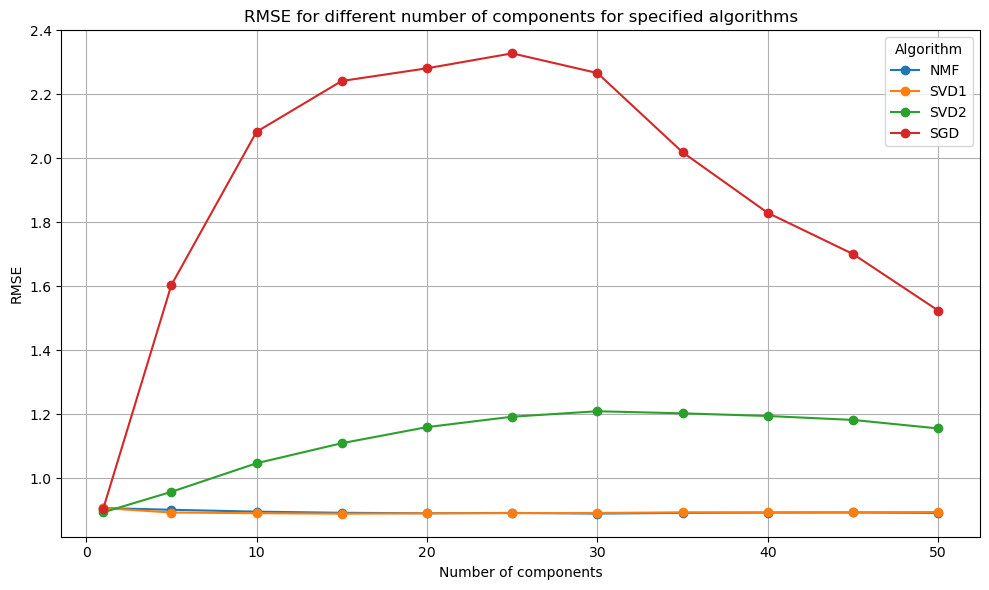

In [21]:
import matplotlib.pyplot as plt

def plot_rmse_for_n_components(results_df):

    plt.figure(figsize=(10, 6))
    
    for alg in results_df["algorithm"].unique():
        df_alg = results_df[results_df["algorithm"] == alg]
        plt.plot(df_alg["n_components"], df_alg["RMSE"], marker='o', label=alg)

    plt.title("RMSE for different number of components for specified algorithms")
    plt.xlabel("Number of components")
    plt.ylabel("RMSE")
    plt.legend(title="Algorithm")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_rmse_for_n_components(results_df)

We can see printed exact values of RMSE for each r value and each model. Based on that I chosed $r=30$ for NMF model and $r=15$ for SVD1.

We can see from that plot that both SVD2 (iterated SVD) and SGD have the best results with small value of $r$. I have checked values of $r$ equal 1, 3, 5, 7, 9 for them as well.

In [5]:
results_df_sgd_svd2 = rmse_for_test_sample(pd.read_csv("data/ratings.csv"), n_components_values=[1, 3, 5, 7, 9], algorithms=["SGD", "SVD2"])

n_components = 1, Algorithm: SGD  , RMSE: 0.9043
n_components = 1, Algorithm: SVD2 , RMSE: 0.8939
n_components = 3, Algorithm: SGD  , RMSE: 1.2851
n_components = 3, Algorithm: SVD2 , RMSE: 0.9142
n_components = 5, Algorithm: SGD  , RMSE: 1.6038
n_components = 5, Algorithm: SVD2 , RMSE: 0.9580
n_components = 7, Algorithm: SGD  , RMSE: 1.9420
n_components = 7, Algorithm: SVD2 , RMSE: 0.9905
n_components = 9, Algorithm: SGD  , RMSE: 2.1406
n_components = 9, Algorithm: SVD2 , RMSE: 1.0304


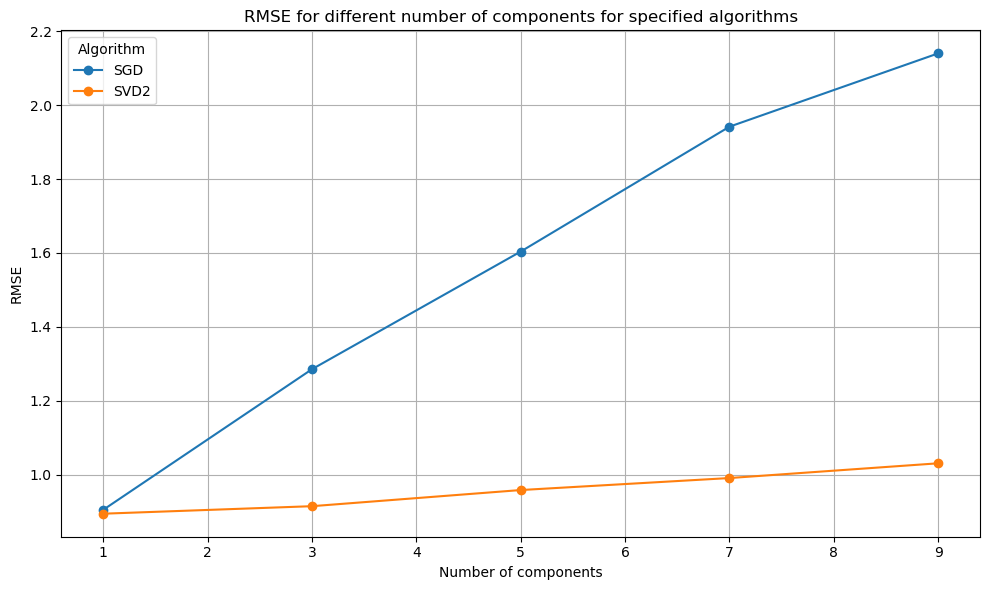

In [6]:
plot_rmse_for_n_components(results_df_sgd_svd2)

Based on that additional tests I chosed $r=1$ for both SVD1 and SGD.

## Choices of parameters for SVD2

My function with training for SVD2 model is presented below.

The stop criteria for iterations of SVD2 is based on changes on predicted data (ratings that were not in original data) made by last iteration. 
The function: np.linalg.norm(Z_new[~mask] - Z_copy[~mask]), compute those changes and compare it with given tol value. If the difference between previous and current matrices approximating $Z$ are smaller then tol value, SVD2 stops. It is possible that it will reach the determined by max_iter limit sooner.

For tests above I chose tol=1e-2.

In [28]:
import numpy as np
from sklearn.decomposition import TruncatedSVD
from modules.helper_functions import build_rating_matrix

def train_svd2_model(train_file, n_components=40, max_iter=500, tol=1e-2, verbose = False):
    Z, user_map, movie_map, mask = build_rating_matrix(train_file)
    Z_copy = Z.copy()         # creating copy to prevent changing Z matrix (in case od alg == ALL)
    
    for iter in range(max_iter):
        # SVD on current approximation
        svd = TruncatedSVD(n_components=n_components, random_state=42)
        svd.fit(Z_copy)

        Sigma2 = np.diag(svd.singular_values_)
        VT = svd.components_
        W = svd.transform(Z_copy) / svd.singular_values_
        H = np.dot(Sigma2, VT)
        Z_approx = np.dot(W, H)

        # Overwriting known data from original matrix Z
        Z_new = Z_approx.copy()
        Z_new[mask] = Z[mask]

        # Stop criteria:    depends on changes on predicted data
        diff = np.linalg.norm(Z_new[~mask] - Z_copy[~mask])
        if diff < tol:
            if verbose == True:
                print(iter)
            break

        Z_copy = Z_new

    return Z_copy, user_map, movie_map, mask

Let us test what value of max_iter for SVD2 will be reached for tol=1e^-2.

In [29]:
import pandas as pd
import numpy as np
import os
import tempfile
from sklearn.metrics import mean_squared_error
#from modules.train_functions import train_svd2_model


def sample_data(df, n_rows=100, random_seed=42):
    df_sample = df.sample(n=n_rows, random_state=random_seed)
    df_test = df_sample[["userId", "movieId", "rating"]].copy()
    df_train = df.drop(df_sample.index)
    return df_train, df_test

def calculate_rmse(true_ratings, predicted_ratings):
    mse = mean_squared_error(true_ratings, predicted_ratings)
    return np.sqrt(mse)



df_ratings = pd.read_csv("data/ratings.csv")
df_train, df_test = sample_data(df_ratings, n_rows=10000)
results = []

with tempfile.NamedTemporaryFile(delete=False, suffix=".csv", mode='w') as tmpfile:
    df_train.to_csv(tmpfile.name, index=False)
    train_file_path = tmpfile.name



Z_approx, user_map, movie_map, mask = train_svd2_model(train_file_path, n_components=10, max_iter=1000, tol=1e-2, verbose=True)

true_ratings = df_test["rating"].values
test_user_movie = df_test[["userId", "movieId"]].values
predicted_ratings = []

for user, movie in test_user_movie:
    if user in user_map and movie in movie_map:
        pred = Z_approx[user_map[user], movie_map[movie]]
    elif user in user_map:
        pred = np.mean(Z_approx[user_map[user], :])
    elif movie in movie_map:
        pred = np.mean(Z_approx[:, movie_map[movie]])
    else:
        pred = np.mean(Z_approx)
    predicted_ratings.append(pred)

rmse = calculate_rmse(true_ratings, predicted_ratings)
print(f"RMSE: {rmse:.4f}")

os.remove(train_file_path)

RMSE: 1.0921


I stopped at max_iter=1000 because of time needed to perform training. The RMSE was good enough.

## Choices of parameters for SGD

For SGD I run tests over parameters: learning rate and number of epochs.

Learning rate determines how big step we take in each iteration toward the optimum (minimum of loss function). We don't want it to be too big because then the algorithm can cross the minimum.
Number of epochs is a number of iterations in SGD. We want it to be big enough to optimize RMSE value. But also, if it's gonna be too big the model can overfit to training data.

I've run some tests with r=10. It's not optimal, but that shouldn't make much difference in those tests.

In [ ]:
import pandas as pd
import numpy as np
import os
import tempfile
from sklearn.metrics import mean_squared_error
from modules.train_functions import train_sgd_model


def sample_data(df, n_rows=100, random_seed=42):
    df_sample = df.sample(n=n_rows, random_state=random_seed)
    df_test = df_sample[["userId", "movieId", "rating"]].copy()
    df_train = df.drop(df_sample.index)
    return df_train, df_test

def calculate_rmse(true_ratings, predicted_ratings):
    mse = mean_squared_error(true_ratings, predicted_ratings)
    return np.sqrt(mse)




def test_sgd_lr_epochs_rmse(df_full, lr_list=[0.001, 0.01, 0.05, 0.1], epochs_list=[100, 500, 1000, 2000], n_components=10):

    df_train, df_test = sample_data(df_full, n_rows=10000)
    results = []

    with tempfile.NamedTemporaryFile(delete=False, suffix=".csv", mode='w') as tmpfile:
        df_train.to_csv(tmpfile.name, index=False)
        train_file_path = tmpfile.name

    for lr in lr_list:
        for n_epochs in epochs_list:
            Z_approx, user_map, movie_map, mask = train_sgd_model(train_file=train_file_path,
                n_components=n_components,
                lr=lr,
                max_iter=n_epochs,
                optimizer_name="Adam",
                tol=0,
                verbose=False
            )

            true_ratings = df_test["rating"].values
            test_user_movie = df_test[["userId", "movieId"]].values
            predicted_ratings = []

            for user, movie in test_user_movie:
                if user in user_map and movie in movie_map:
                    pred = Z_approx[user_map[user], movie_map[movie]]
                elif user in user_map:
                    pred = np.mean(Z_approx[user_map[user], :])
                elif movie in movie_map:
                    pred = np.mean(Z_approx[:, movie_map[movie]])
                else:
                    pred = np.mean(Z_approx)
                predicted_ratings.append(pred)

            rmse = calculate_rmse(true_ratings, predicted_ratings)
            print(f"LR: {lr}, Epochs: {n_epochs}, RMSE: {rmse:.4f}")

            results.append({"learning_rate": lr, "n_epochs": n_epochs, "RMSE": rmse})

    os.remove(train_file_path)
    return pd.DataFrame(results)


df_ratings = pd.read_csv("data/ratings.csv")
results = test_sgd_lr_epochs_rmse(df_ratings)

# Posortuj po RMSE (najlepsze na górze)
print(results.sort_values("RMSE"))

LR: 0.001, Epochs: 100, RMSE: 2.2767
LR: 0.001, Epochs: 500, RMSE: 1.1822
LR: 0.001, Epochs: 1000, RMSE: 1.0208
LR: 0.001, Epochs: 2000, RMSE: 0.9940
LR: 0.01, Epochs: 100, RMSE: 1.0132
LR: 0.01, Epochs: 500, RMSE: 1.0350
LR: 0.01, Epochs: 1000, RMSE: 1.1385
LR: 0.01, Epochs: 2000, RMSE: 1.3422
LR: 0.05, Epochs: 100, RMSE: 1.0066
LR: 0.05, Epochs: 500, RMSE: 1.2935
LR: 0.05, Epochs: 1000, RMSE: 1.5653
LR: 0.05, Epochs: 2000, RMSE: 2.0438
LR: 0.1, Epochs: 100, RMSE: 1.0852
LR: 0.1, Epochs: 500, RMSE: 1.4695
LR: 0.1, Epochs: 1000, RMSE: 1.8325
LR: 0.1, Epochs: 2000, RMSE: 2.3966
    learning_rate  n_epochs      RMSE
3           0.001      2000  0.993994
8           0.050       100  1.006630
4           0.010       100  1.013235
2           0.001      1000  1.020789
5           0.010       500  1.034973
12          0.100       100  1.085161
6           0.010      1000  1.138521
1           0.001       500  1.182181
9           0.050       500  1.293495
7           0.010      2000  1.34218

From first tests we can see, that the best result was made for lr=0.001 and n_epochs=2000. I've checked more values below.

In [ ]:
df_ratings = pd.read_csv("data/ratings.csv")
results = test_sgd_lr_epochs_rmse(df_ratings, lr_list=[0.0001, 0.005, 0.001], epochs_list=[2000, 4000])

# Posortuj po RMSE (najlepsze na górze)
print(results.sort_values("RMSE"))

LR: 0.0001, Epochs: 2000, RMSE: 1.7256
LR: 0.0001, Epochs: 4000, RMSE: 1.2139
LR: 0.005, Epochs: 2000, RMSE: 1.1668
LR: 0.005, Epochs: 4000, RMSE: 1.4557
LR: 0.001, Epochs: 2000, RMSE: 0.9940
LR: 0.001, Epochs: 4000, RMSE: 1.0613
   learning_rate  n_epochs      RMSE
4         0.0010      2000  0.993994
5         0.0010      4000  1.061279
2         0.0050      2000  1.166840
1         0.0001      4000  1.213889
3         0.0050      4000  1.455695
0         0.0001      2000  1.725609


Based on those additional tests, I'm gonna stay with lr=0.001, n_epochs=2000 for SGD model.

## Best results RMSE for data
I present below RMSE for best models with best parameters that I found.

In [30]:
import pandas as pd
import numpy as np
import os
import tempfile
from sklearn.metrics import mean_squared_error
from modules.train_functions import train_nmf_model, train_svd1_model, train_svd2_model, train_sgd_model


def sample_data(df, n_rows=100, random_seed=42):
    df_sample = df.sample(n=n_rows, random_state=random_seed)
    df_test = df_sample[["userId", "movieId", "rating"]].copy()
    df_train = df.drop(df_sample.index)
    return df_train, df_test

def calculate_rmse(true_ratings, predicted_ratings):
    mse = mean_squared_error(true_ratings, predicted_ratings)
    return np.sqrt(mse)



df_ratings = pd.read_csv("data/ratings.csv")
df_train, df_test = sample_data(df_ratings, n_rows=10000)
results = []

with tempfile.NamedTemporaryFile(delete=False, suffix=".csv", mode='w') as tmpfile:
    df_train.to_csv(tmpfile.name, index=False)
    train_file_path = tmpfile.name

algorithms = ["NMF", "SVD1", "SVD2", "SGD"]
counter = 0

for alg in [train_nmf_model(train_file_path), train_svd1_model(train_file_path), train_svd2_model(train_file_path), train_sgd_model(train_file_path)]:
    Z_approx, user_map, movie_map, mask = alg

    true_ratings = df_test["rating"].values
    test_user_movie = df_test[["userId", "movieId"]].values
    predicted_ratings = []

    for user, movie in test_user_movie:
        if user in user_map and movie in movie_map:
            pred = Z_approx[user_map[user], movie_map[movie]]
        elif user in user_map:
            pred = np.mean(Z_approx[user_map[user], :])
        elif movie in movie_map:
            pred = np.mean(Z_approx[:, movie_map[movie]])
        else:
            pred = np.mean(Z_approx)
        predicted_ratings.append(pred)

    rmse = calculate_rmse(true_ratings, predicted_ratings)
    print(f"Best model for algorithm: {algorithms[counter]}, RMSE: {rmse:.4f}")
    counter+=1


os.remove(train_file_path)

c:\Users\olako\anaconda3\envs\my_ml_project_env\Lib\site-packages\sklearn\decomposition\_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


Epoch 1/5000, Loss: 43.4064
Epoch 100/5000, Loss: 12.1317
Epoch 200/5000, Loss: 4.6988
Epoch 300/5000, Loss: 2.2759
Epoch 400/5000, Loss: 1.3287
Epoch 500/5000, Loss: 0.9268
Epoch 600/5000, Loss: 0.7513
Epoch 700/5000, Loss: 0.6745
Epoch 800/5000, Loss: 0.6411
Epoch 900/5000, Loss: 0.6267
Epoch 1000/5000, Loss: 0.6205
Epoch 1100/5000, Loss: 0.6178
Epoch 1200/5000, Loss: 0.6165
Epoch 1300/5000, Loss: 0.6160
Epoch 1400/5000, Loss: 0.6157
Epoch 1500/5000, Loss: 0.6156
Epoch 1600/5000, Loss: 0.6155
Epoch 1700/5000, Loss: 0.6155
Epoch 1800/5000, Loss: 0.6155
Epoch 1900/5000, Loss: 0.6155
Epoch 2000/5000, Loss: 0.6154
Epoch 2100/5000, Loss: 0.6154
Epoch 2200/5000, Loss: 0.6154
Epoch 2300/5000, Loss: 0.6154
Epoch 2400/5000, Loss: 0.6154
Epoch 2500/5000, Loss: 0.6154
Epoch 2600/5000, Loss: 0.6154
Epoch 2700/5000, Loss: 0.6154
Early stopping at epoch 2775, Δ = 0.008349
Best model for algorithm: NMF, RMSE: 0.8932
Best model for algorithm: SVD1, RMSE: 0.8934
Best model for algorithm: SVD2, RMSE: 